LN Project - Baseline

Imports

In [1]:
import pandas as pd
import numpy as np
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

Data Loading & Cleaning

In [2]:
# 1. Load dataset safely
df = pd.read_csv('train.csv', sep=';', on_bad_lines='skip', quotechar='"')

# 2. Strip whitespaces
df.columns = df.columns.str.strip()
df['medical_specialty'] = df['medical_specialty'].str.strip()

# 3. Filter valid 12 specialties
valid_specialties = df['medical_specialty'].value_counts()
valid_specialties = valid_specialties[valid_specialties > 10].index.tolist()
df = df[df['medical_specialty'].isin(valid_specialties)].copy().reset_index(drop=True)

# 4. Fill missing values with empty strings
df['sample_name'] = df['sample_name'].fillna("")
df['description'] = df['description'].fillna("")
df['keywords'] = df['keywords'].fillna("")
df['transcription'] = df['transcription'].fillna("")

Text Pre-processing and Feature Engineering

In [3]:
# 5. Feature Engineering: Weighted Concatenation
# Boosting sample_name (2x) and keywords (2x) to prevent dilution by long transcriptions
df['weighted_text'] = (
    df['sample_name'] + " " + df['sample_name'] + " " +
    df['description'] + " " +
    df['keywords'] + " " + df['keywords'] + " " +
    df['transcription']
)

# 6. Medical Text Normalization (Preserving complete words & negations)
def clean_medical_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    # Replace non-alphanumeric chars with space, preserving alphanumeric tokens
    text = re.sub(r'[^\w\s]', ' ', text)
    return " ".join(text.split())

df['clean_weighted_text'] = df['weighted_text'].apply(clean_medical_text)

print(f"Total samples processed: {len(df)}")
print("Sample preview:")
print(df['clean_weighted_text'].iloc[0][:300] + "...")

Total samples processed: 2613
Sample preview:
chest pain cardiac consult chest pain cardiac consult chest pain possible syncopal spells she has been having multiple cardiovascular complaints including chest pains which feel like cramps and sometimes like a dull ache which will last all day long cardiovascular pulmonary chest pain syncopal echoc...


Train / Validation Split

In [4]:
X_train, X_val, y_train, y_val = train_test_split(
    df['clean_weighted_text'],
    df['medical_specialty'],
    test_size=0.20,
    random_state=42,
    stratify=df['medical_specialty']
)

print(f"Train set: {len(X_train)} samples")
print(f"Validation set: {len(X_val)} samples")

Train set: 2090 samples
Validation set: 523 samples


TF-IDF Vectorization with N-Grams

In [5]:
# Unigrams and Bigrams, with sublinear term-frequency scaling
tfidf = TfidfVectorizer(
    max_features=35000,
    ngram_range=(1, 2),
    sublinear_tf=True,
    min_df=2
)

X_train_vec = tfidf.fit_transform(X_train)
X_val_vec = tfidf.transform(X_val)

print(f"Feature matrix dimension: {X_train_vec.shape}")

Feature matrix dimension: (2090, 35000)


Model Training & Evaluation

In [ ]:
# LinearSVC with balanced penalty to address class imbalance
model = LinearSVC(C=0.4, class_weight='balanced', random_state=42)
model.fit(X_train_vec, y_train)

# Predictions & Metrics
y_pred = model.predict(X_val_vec)
acc = accuracy_score(y_val, y_pred)

print("=" * 60)
print(f"STEP 1 ACCURACY: {acc * 100:.2f}%")
print("=" * 60)
print("\nClassification Report:")
print(classification_report(y_val, y_pred, digits=3))

STEP 1 ACCURACY: 59.27%

Classification Report:
                          precision    recall  f1-score   support

Cardiovascular-Pulmonary      0.608     0.750     0.672        60
             Dermatology      0.833     1.000     0.909         5
        Gastroenterology      0.571     0.842     0.681        38
        General Medicine      0.691     0.927     0.792        41
               Neurology      0.489     0.611     0.543        36
            Neurosurgery      0.280     0.438     0.341        16
   Obstetrics-Gynecology      0.561     0.852     0.676        27
           Ophthalmology      0.542     0.929     0.684        14
              Orthopedic      0.468     0.492     0.479        59
   Psychiatry-Psychology      0.636     0.875     0.737         8
               Radiology      0.571     0.455     0.506        44
                 Surgery      0.775     0.394     0.523       175

                accuracy                          0.593       523
               macro avg  

Output Analysis

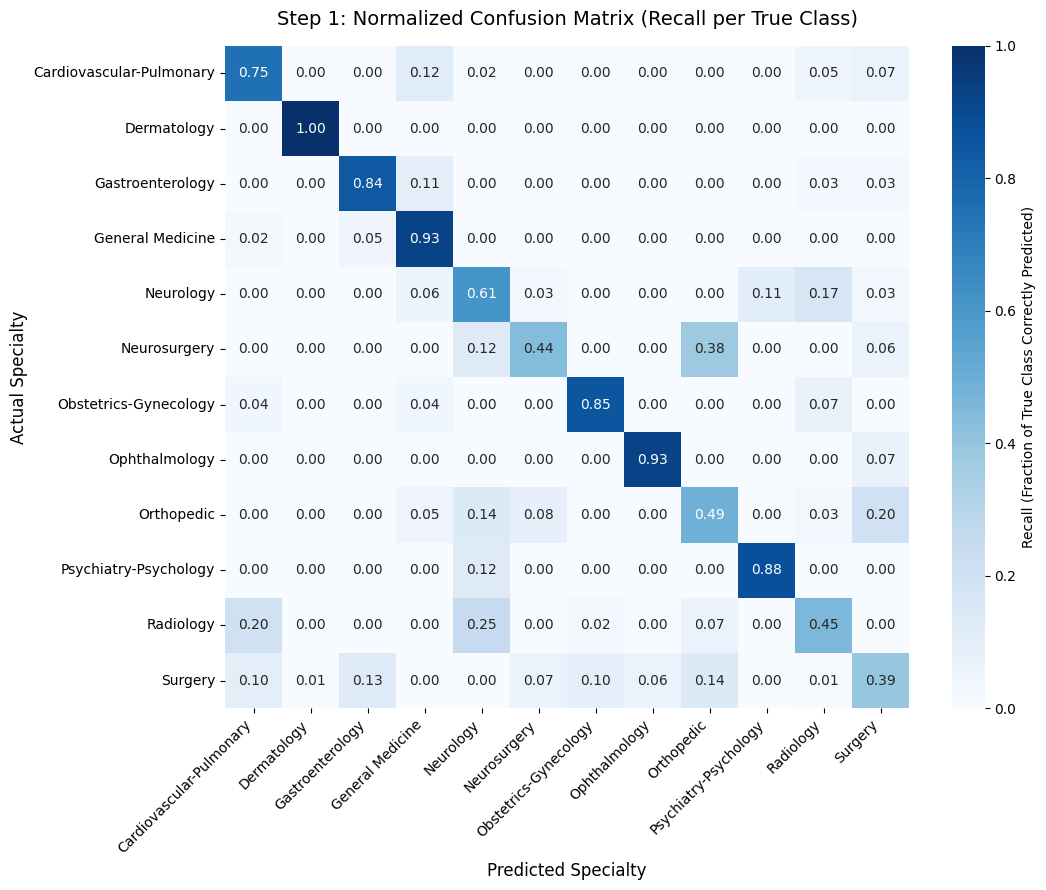

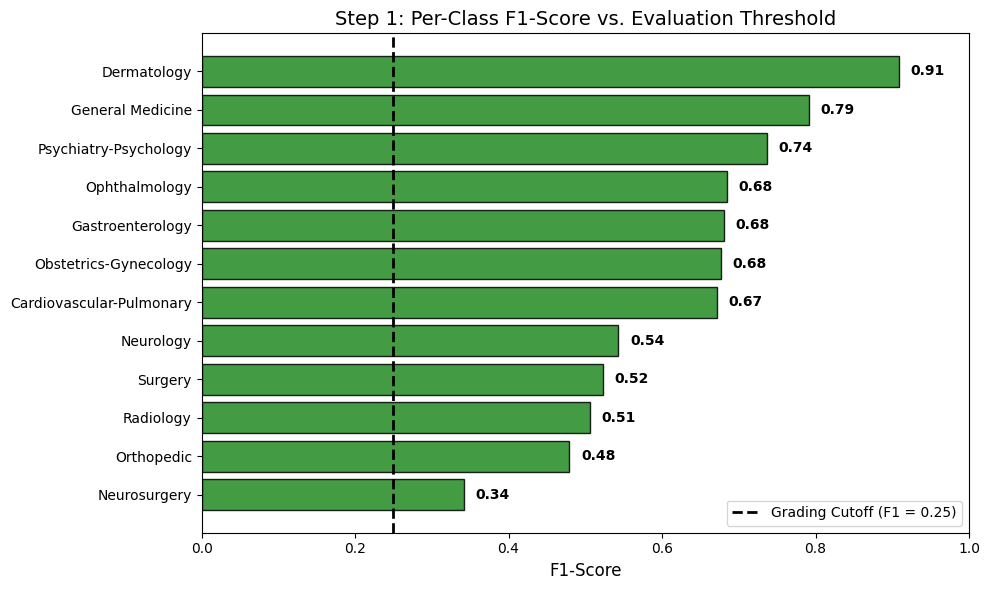

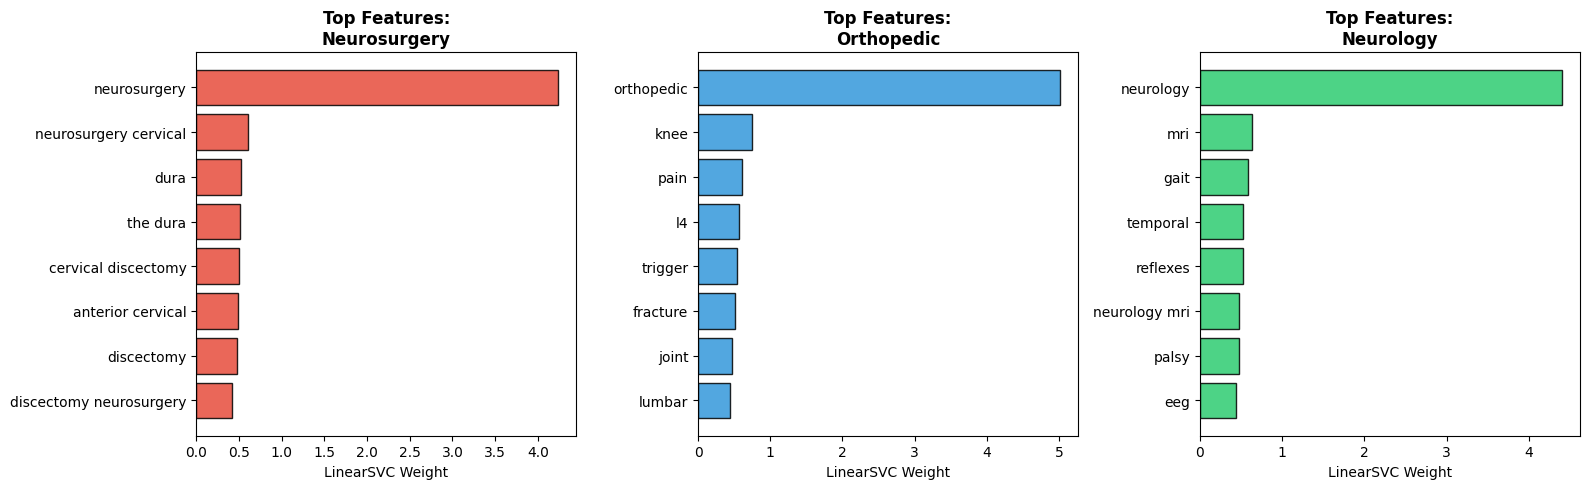

STATISTICAL PERFORMANCE BREAKDOWN BY SPECIALTY


,Specialty,Support (Actual),Correct,Total Predicted,Precision,Recall,F1-Score,Meets Threshold?
1,Dermatology,5,5,6,0.833,1.000,0.909,YES
3,General Medicine,41,38,55,0.691,0.927,0.792,YES
9,Psychiatry-Psychology,8,7,11,0.636,0.875,0.737,YES
7,Ophthalmology,14,13,24,0.542,0.929,0.684,YES
2,Gastroenterology,38,32,56,0.571,0.842,0.681,YES
6,Obstetrics-Gynecology,27,23,41,0.561,0.852,0.676,YES
0,Cardiovascular-Pulmonary,60,45,74,0.608,0.750,0.672,YES
4,Neurology,36,22,45,0.489,0.611,0.543,YES
11,Surgery,175,69,89,0.775,0.394,0.523,YES
10,Radiology,44,20,35,0.571,0.455,0.506,YES


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Distinct label list sorted alphabetically
labels = sorted(df['medical_specialty'].unique())

# ==============================================================================
# Plot 1: Normalized Confusion Matrix Heatmap (Recall per True Class)
# ==============================================================================
cm_norm = confusion_matrix(y_val, y_pred, labels=labels, normalize='true')

plt.figure(figsize=(11, 9))
sns.heatmap(
    cm_norm, 
    annot=True, 
    fmt='.2f', 
    cmap='Blues', 
    xticklabels=labels, 
    yticklabels=labels,
    cbar_kws={'label': 'Recall (Fraction of True Class Correctly Predicted)'}
)
plt.title('Step 1: Normalized Confusion Matrix (Recall per True Class)', fontsize=14, pad=15)
plt.xlabel('Predicted Specialty', fontsize=12)
plt.ylabel('Actual Specialty', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ==============================================================================
# Plot 2: Per-Class F1 Score vs. 25% Threshold Bar Chart
# ==============================================================================
report_dict = classification_report(y_val, y_pred, output_dict=True)

f1_data = pd.DataFrame({
    'Specialty': labels,
    'F1_Score': [report_dict[cls]['f1-score'] for cls in labels]
}).sort_values(by='F1_Score', ascending=True)

plt.figure(figsize=(10, 6))
bar_colors = ['crimson' if score < 0.25 else 'forestgreen' for score in f1_data['F1_Score']]
bars = plt.barh(f1_data['Specialty'], f1_data['F1_Score'], color=bar_colors, edgecolor='black', alpha=0.85)

# The critical 0.25 cutoff from the course evaluation criteria
plt.axvline(x=0.25, color='black', linestyle='--', linewidth=2, label='Grading Cutoff (F1 = 0.25)')
plt.title('Step 1: Per-Class F1-Score vs. Evaluation Threshold', fontsize=14)
plt.xlabel('F1-Score', fontsize=12)
plt.xlim(0, 1.0)

for bar, score in zip(bars, f1_data['F1_Score']):
    plt.text(bar.get_width() + 0.015, bar.get_y() + bar.get_height()/2, f"{score:.2f}", va='center', fontsize=10, fontweight='bold')

plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

# ==============================================================================
# Plot 3: Top Discriminative N-Gram Features per Class
# ==============================================================================
feature_names = np.array(tfidf.get_feature_names_out())
svm_coefficients = model.coef_
class_index = {cls: idx for idx, cls in enumerate(model.classes_)}

confused_classes = ['Neurosurgery', 'Orthopedic', 'Neurology']
colors = ['#e74c3c', '#3498db', '#2ecc71']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
top_k = 8

for ax, cls_name, col in zip(axes, confused_classes, colors):
    idx = class_index[cls_name]
    top_indices = np.argsort(svm_coefficients[idx])[-top_k:]
    words = feature_names[top_indices]
    weights = svm_coefficients[idx][top_indices]
    
    ax.barh(words, weights, color=col, edgecolor='black', alpha=0.85)
    ax.set_title(f'Top Features:\n{cls_name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('LinearSVC Weight', fontsize=10)

plt.tight_layout()
plt.show()

# ==============================================================================
# Output Statistics: Per-Class Breakdown Table
# ==============================================================================
cm_raw = confusion_matrix(y_val, y_pred, labels=labels)

stats_summary = []
for i, cls in enumerate(labels):
    actual_count = int(np.sum(cm_raw[i, :]))
    correct_count = int(cm_raw[i, i])
    predicted_count = int(np.sum(cm_raw[:, i]))
    prec = report_dict[cls]['precision']
    rec = report_dict[cls]['recall']
    f1 = report_dict[cls]['f1-score']
    meets_cutoff = "YES" if f1 >= 0.25 else "NO (<0.25)"
    
    stats_summary.append({
        'Specialty': cls,
        'Support (Actual)': actual_count,
        'Correct': correct_count,
        'Total Predicted': predicted_count,
        'Precision': round(prec, 3),
        'Recall': round(rec, 3),
        'F1-Score': round(f1, 3),
        'Meets Threshold?': meets_cutoff
    })

stats_df = pd.DataFrame(stats_summary).sort_values(by='F1-Score', ascending=False)

print("=" * 90)
print("STATISTICAL PERFORMANCE BREAKDOWN BY SPECIALTY")
print("=" * 90)
display(stats_df)